## "Анализ эффективности маркетинговых кампаний в социальных сетях для выявления закономерностей вовлечения аудитории".

### 2.1. Проанализировать цели проекта. С точки зрения бизнеса, определить бизнес-цели и критерии их достижения, с точки зрения науки, задать границы исследования в рамках выбранной темы, описать объект и предмет исследования, сформулировать аналитическую гипотезу.

**Бизнес-проблема.**

Высокие показатели охвата, кликов и вовлечённости не всегда означают эффективное использование рекламного бюджета. Поэтому необходимо определить, какие характеристики рекламных кампаний и аудитории связаны с более высокой финансовой отдачей.

**Бизнес-цель проекта.**

Повысить эффективность расходования рекламного бюджета за счёт выявления наиболее результативных маркетинговых стратегий, категорий товаров и сегментов покупателей.

**Критерии достижения бизнес-цели.**

Предварительно цель считается достигнутой, если применение результатов анализа позволит:

* увеличить финансовую отдачу от рекламных расходов не менее чем на 10%
* снизить стоимость привлечения или целевого действия не менее чем на 10%
* выявить категории товаров, покупателей и маркетинговые стратегии, финансовая эффективность которых превышает средний уровень не менее чем на 15%
* определить направления для перераспределения не менее 15% рекламного бюджета из менее эффективных кампаний в более эффективные

**Практическая ценность.**

Результаты исследования могут использоваться для выявления неэффективных рекламных расходов, выбора наиболее результативных маркетинговых стратегий и поддержки решений по перераспределению рекламного бюджета между категориями товаров и сегментами покупателей.

**Объект исследования.**

Онлайн-маркетинговые кампании по продвижению товаров среди различных сегментов покупателей.

**Предмет исследования.**

Алгоритмы интеллектуального анализа данных и машинного обучения для оценки финансовой эффективности онлайн-маркетинговых кампаний и выявления наиболее результативных маркетинговых стратегий.

**Границы исследования.**

Исследование ограничивается онлайн-маркетинговыми кампаниями по продвижению товаров, для которых доступны сведения о рекламных расходах, результатах кампании, категориях товаров и характеристиках покупателей. Предполагается анализировать кампании в социальных сетях и других цифровых рекламных каналах. Конкретные платформы, категории товаров, сегменты покупателей и временной период будут уточнены после окончательного выбора источников данных.

**Исследовательский вопрос.**

Какие характеристики рекламных кампаний, каналов и аудитории связаны с различиями в финансовой эффективности рекламы?

**Гипотеза.**

H1: ROAS статистически значимо различается хотя бы между платформами, типами маркетинговых кампаний или сегментами аудитории. 

H0: ROAS статистически не связан характеристиками рекламных и маркетинговых кампаний, платформами или сегментами аудитории, а их использование не позволяет улучшить прогноз финансовой эффективности.

### 2.2. Подбор и изучение источников данных

Для исследования выбраны четыре независимых фрагмента данных, характеризующих финансовую эффективность платной рекламы, количественную вовлечённость аудитории видеоконтента, текстовую реакцию пользователей и рекламные креативы. Основным источником является набор по платной поисковой кампании, содержащий расходы, доход и прибыль/убыток. Остальные источники используются как дополнительные фрагменты.

| Источник | Характеризуемая область | Структура данных | Формат |
|---|---|---|---|
| Shopping Mall Paid Search Campaign Dataset | финансовая эффективность платной рекламной кампании | записи рекламных групп по месяцам | CSV |
| Trending YouTube Video Statistics | вовлечённость аудитории видеоконтента | записи видео и справочник категорий | CSV + JSON |
| Twitter US Airline Sentiment | текстовая реакция аудитории | сообщения пользователей и метаданные | CSV |
| ADS-16 Computational Advertising Dataset | рекламные изображения и оценки креативов | изображения, категории и рейтинги | PNG + CSV |

Источники доступны публично через Kaggle. Файлы загружаются программно и сохраняются локально.

In [1]:
from pathlib import Path
import io
import json
import zipfile
import requests
import pandas as pd
from PIL import Image
from IPython.display import display

DATA_DIR = Path("course_data")
DATA_DIR.mkdir(exist_ok=True)

def download_kaggle_file(dataset_ref, filename, local_name=None):
    """Загрузка одного публичного файла Kaggle с локальным кешированием."""
    local_path = DATA_DIR / (local_name or Path(filename).name)
    if local_path.exists() and local_path.stat().st_size > 0:
        return local_path
    url = (
        "https://www.kaggle.com/api/v1/datasets/download/"
        f"{dataset_ref}?filename={requests.utils.quote(filename, safe='')}"
    )
    response = requests.get(url, timeout=180)
    response.raise_for_status()
    content = response.content
    if content[:2] == b"PK":
        with zipfile.ZipFile(io.BytesIO(content)) as archive:
            names = archive.namelist()
            if not names:
                raise ValueError(f"Пустой архив: {filename}")
            content = archive.read(names[0])
    local_path.write_bytes(content)
    return local_path

def show_table_profile(df, name, head_rows=3):
    print(f"{name}: shape={df.shape}")
    print("Столбцы:", list(df.columns))
    print("Типы данных:")
    display(df.dtypes.rename("dtype").to_frame())
    print("Пропуски:")
    display(df.isna().sum().rename("missing").to_frame())
    print(f"Первые {head_rows} строки:")
    display(df.head(head_rows))

### Источник 1. Платная рекламная кампания

Shopping Mall Paid Search Campaign Dataset опубликован на Kaggle пользователем `marceaxl82`. В описании источника указано, что набор содержит данные пятимесячной платной поисковой кампании 2021 года, включая рекламные расходы, доход, конверсии и показатели объявлений.

Источник непосредственно связан с бизнес-целью работы: по полям `Revenue` и `Cost` может быть рассчитан показатель ROAS как отношение дохода к рекламным расходам. При интерпретации необходимо отдельно учитывать назначение полей `Revenue`, `Sale Amount` и `P&L`.

In [2]:
campaign_path = download_kaggle_file(
    "marceaxl82/shopping-mall-paid-search-campaign-dataset",
    "final_shop_6modata.csv",
    "campaign.csv",
)
campaign = pd.read_csv(campaign_path)
show_table_profile(campaign, "Рекламная кампания")

print("Число рекламных групп:", campaign["Ad Group"].nunique())
print("Месяцы:", sorted(campaign["Month"].unique().tolist()))
print("Диапазон Cost:", (campaign["Cost"].min(), campaign["Cost"].max()))
print("Диапазон Revenue:", (campaign["Revenue"].min(), campaign["Revenue"].max()))

Рекламная кампания: shape=(190, 12)
Столбцы: ['Ad Group', 'Month', 'Impressions', 'Clicks', 'CTR', 'Conversions', 'Conv Rate', 'Cost', 'CPC', 'Revenue', 'Sale Amount', 'P&L']
Типы данных:


,dtype
Ad Group,object
Month,object
Impressions,int64
Clicks,int64
CTR,float64
Conversions,int64
Conv Rate,float64
Cost,int64
CPC,float64
Revenue,int64


Пропуски:


,missing
Ad Group,0
Month,0
Impressions,0
Clicks,0
CTR,0
Conversions,0
Conv Rate,0
Cost,0
CPC,0
Revenue,0


Первые 3 строки:


,Ad Group,Month,Impressions,Clicks,CTR,Conversions,Conv Rate,Cost,CPC,Revenue,Sale Amount,P&L
0,Shop - 1:1 - Desk - [shop coupon code],July,16038,6504,0.41,1166,0.10,6669,1.03,6402,136770.05,-267.086
1,Shop - 1:1 - Desk - [shop coupon],July,36462,14367,0.39,2188,0.09,13746,0.96,13262,283215.21,-483.951
2,Shop - 1:1 - Desk - [shop discount code],July,3635,1458,0.40,248,0.09,1606,1.10,1723,39165.46,117.136


Число рекламных групп: 40
Месяцы: ['August', 'July', 'November', 'October', 'September']
Диапазон Cost: (1, 43542)
Диапазон Revenue: (0, 42440)


Существенные признаки источника 1 классифицируются следующим образом: `Ad Group` - категориальная шкала; `Month` - интервальная шкала календарного времени; `Impressions`, `Clicks` и `Conversions` - абсолютная шкала; `CTR`, `Conv Rate`, `CPC`, `Cost`, `Revenue`, `Sale Amount` и `P&L` - шкала отношений. Идентификатор кампании в наборе отсутствует, поэтому рекламная группа используется как категориальный аналитический признак.

### Источник 2. Вовлечённость аудитории видеоконтента

Trending YouTube Video Statistics опубликован на Kaggle пользователем `datasnaek`. Для анализа выбраны американский CSV-фрагмент `USvideos.csv` и JSON-справочник `US_category_id.json`. CSV содержит показатели просмотров, реакций и комментариев, а JSON позволяет раскрыть смысл числового `category_id` через название категории. Связь между файлами выполняется по идентификатору категории.

In [3]:
youtube_csv_path = download_kaggle_file(
    "datasnaek/youtube-new", "USvideos.csv", "USvideos.csv"
)
youtube_json_path = download_kaggle_file(
    "datasnaek/youtube-new", "US_category_id.json", "US_category_id.json"
)
youtube = pd.read_csv(youtube_csv_path)
show_table_profile(youtube, "YouTube US videos")

category_data = json.loads(youtube_json_path.read_text(encoding="utf-8"))
print("Тип корневого JSON-объекта:", type(category_data).__name__)
print("Ключи верхнего уровня:", list(category_data.keys()))
print("Количество объектов items:", len(category_data["items"]))
print("Пример элемента:")
display(pd.json_normalize(category_data["items"]).head(2))

YouTube US videos: shape=(40949, 16)
Столбцы: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description']
Типы данных:


,dtype
video_id,object
trending_date,object
title,object
channel_title,object
category_id,int64
publish_time,object
tags,object
views,int64
likes,int64
dislikes,int64


Пропуски:


,missing
video_id,0
trending_date,0
title,0
channel_title,0
category_id,0
publish_time,0
tags,0
views,0
likes,0
dislikes,0


Первые 3 строки:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...


Тип корневого JSON-объекта: dict
Ключи верхнего уровня: ['kind', 'etag', 'items']
Количество объектов items: 32
Пример элемента:


,kind,etag,id,snippet.channelId,snippet.title,snippet.assignable
0,youtube#videoCategory,"""m2yskBQFythfE4irbTIeOgYYfBU/Xy1mB4_yLrHy_BmKm...",1,UCBR8-60-B28hp2BmDPdntcQ,Film & Animation,True
1,youtube#videoCategory,"""m2yskBQFythfE4irbTIeOgYYfBU/UZ1oLIIz2dxIhO45Z...",2,UCBR8-60-B28hp2BmDPdntcQ,Autos & Vehicles,True


Для источника 2 `video_id` является номинальной шкалой (ID), `title`, `tags`, `description` и ссылка на миниатюру - контентной, `channel_title` и название категории - категориальной, `trending_date` и `publish_time` - интервальной, `views`, `likes`, `dislikes` и `comment_count` - абсолютной, а `comments_disabled`, `ratings_disabled` и `video_error_or_removed` - дихотомической. Источник подходит для оценки вовлечённости, но сам по себе не содержит рекламных расходов и ROAS.

### Источник 3. Текстовая реакция аудитории

Twitter US Airline Sentiment опубликован на Kaggle организацией Crowdflower. Набор содержит сообщения пользователей, авиакомпанию, целевую тональность, уверенность разметки, причины негативной реакции и метаданные публикации. Это дополнительный фрагмент для анализа содержания пользовательской реакции.

In [4]:
airline_path = download_kaggle_file(
    "crowdflower/twitter-airline-sentiment", "Tweets.csv", "Tweets.csv"
)
airline = pd.read_csv(airline_path)
show_table_profile(airline, "Twitter US Airline Sentiment")
print("Уникальные авиакомпании:", airline["airline"].nunique())
print("Распределение тональности:")
display(airline["airline_sentiment"].value_counts().rename("count").to_frame())

Twitter US Airline Sentiment: shape=(14640, 15)
Столбцы: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']
Типы данных:


,dtype
tweet_id,int64
airline_sentiment,object
airline_sentiment_confidence,float64
negativereason,object
negativereason_confidence,float64
airline,object
airline_sentiment_gold,object
name,object
negativereason_gold,object
retweet_count,int64


Пропуски:


,missing
tweet_id,0
airline_sentiment,0
airline_sentiment_confidence,0
negativereason,5462
negativereason_confidence,4118
airline,0
airline_sentiment_gold,14600
name,0
negativereason_gold,14608
retweet_count,0


Первые 3 строки:


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)


Уникальные авиакомпании: 6
Распределение тональности:


,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


В источнике 3 `tweet_id` и `name` относятся к номинальной шкале (ID), `text` и координаты - к контентной, `airline` и `negativereason` - к категориальной, `airline_sentiment` - к категориальной, `airline_sentiment_confidence` и `negativereason_confidence` - к шкале отношений, `retweet_count` - к абсолютной, `tweet_created` - к интервальной. Пропуски в причинах негативной реакции и географических метаданных являются содержательными и не должны автоматически трактоваться как ошибки.

### Источник 4. Рекламные креативы

ADS-16 Computational Advertising Dataset опубликован на Kaggle пользователем Giorgio Roffo. В описании источника указаны 300 реальных рекламных объявлений, 20 категорий и оценки объявлений пользователями. Полный архив велик, поэтому в notebook загружается небольшой воспроизводимый фрагмент изображений и один файл рейтингов. Такой объём достаточен для проверки структуры и базовых характеристик.

Количество локально проверенных изображений: 2
ads16_ad_1.png size= (500, 500) mode= RGB
ads16_ad_2.png size= (500, 500) mode= RGB
Файл рейтингов: ads16_U0001_RT.csv
Количество строк в локальном фрагменте: 3
Первые две строки:
"Cat0";"Cat1";"Cat2";"Cat3";"Cat4";"Cat5";"Cat6";"Cat7";"Cat8";"Cat9";"Cat10";"Cat11";"Cat12";"Cat13";"Cat14";"Cat15";"Cat16";"Cat17";"Cat18";"Cat19"
"Clothing & Shoes";"Automotive";"Baby Products";"Health & Beauty";"Media (BMVD)";"Consumer Electronics";"Console & Video Games";"DIY & Tools";"Garden & Outdoor living";"Grocery";"Kitchen & Home";"Betting";"Jewellery & Watches";"Musical Instruments";"Office Products";"Pet Supplies";"Computer Software";"Sports & Outdoors";"Toys & Games";"Dating Sites"

Изображения:


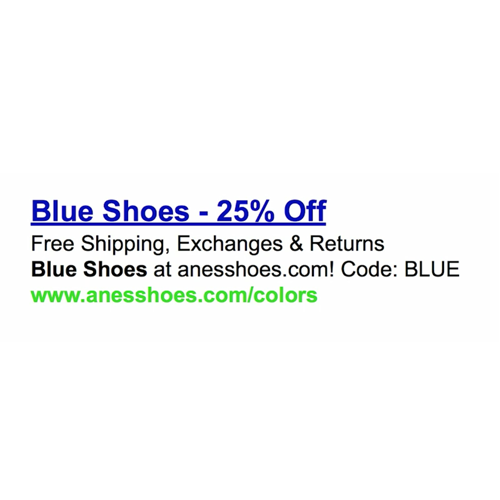

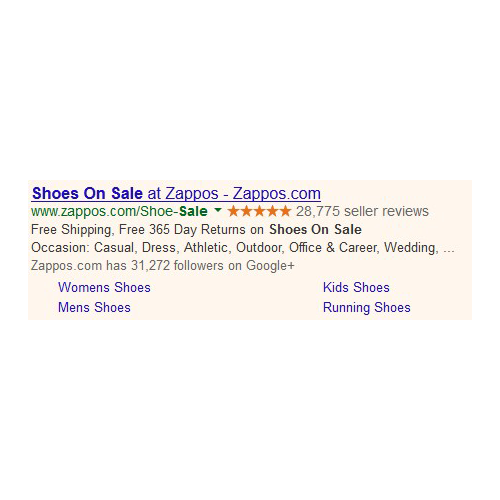

In [5]:
ADS_REF = "groffo/ads16-dataset"
ADS_ROOT = "ADS16_Benchmark_part1/ADS16_Benchmark_part1/"
ratings_path = download_kaggle_file(
    ADS_REF,
    ADS_ROOT + "Corpus/Corpus/U0001/U0001-RT.csv",
    "ads16_U0001_RT.csv",
)

image_paths = []
for image_number in (1, 2):
    image_paths.append(download_kaggle_file(
        ADS_REF,
        ADS_ROOT + f"Ads/Ads/1/{image_number}.png",
        f"ads16_ad_{image_number}.png",
    ))

print("Количество локально проверенных изображений:", len(image_paths))
for path in image_paths:
    with Image.open(path) as image:
        print(path.name, "size=", image.size, "mode=", image.mode)

ratings_text = ratings_path.read_text(encoding="utf-8", errors="replace")
ratings_lines = ratings_text.splitlines()
print("Файл рейтингов:", ratings_path.name)
print("Количество строк в локальном фрагменте:", len(ratings_lines))
print("Первые две строки:")
print("\n".join(ratings_lines[:2]))
print("\nИзображения:")
for path in image_paths:
    display(Image.open(path))

#### Анализ структуры, описательной статистики и функциональных зависимостей

До выполнения полноценной очистки необходимо определить типичные значения признаков, диапазоны и возможные связи между полями. Это позволяет обосновать последующие решения о приведении типов, нормализации, обработке пропусков и контроле аномальных наблюдений. 

In [6]:
from contextlib import redirect_stdout
from io import StringIO

def show_info_and_describe(df, name):
    print(f"{name}: info()")
    buffer = StringIO()
    with redirect_stdout(buffer):
        df.info()
    print(buffer.getvalue())
    print(f"{name}: describe() для числовых признаков")
    display(df.describe().T)

show_info_and_describe(campaign, "Рекламная кампания")
show_info_and_describe(youtube, "YouTube US videos")
show_info_and_describe(airline, "Twitter US Airline Sentiment")

Рекламная кампания: info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Ad Group     190 non-null    object 
 1   Month        190 non-null    object 
 2   Impressions  190 non-null    int64  
 3   Clicks       190 non-null    int64  
 4   CTR          190 non-null    float64
 5   Conversions  190 non-null    int64  
 6   Conv Rate    190 non-null    float64
 7   Cost         190 non-null    int64  
 8   CPC          190 non-null    float64
 9   Revenue      190 non-null    int64  
 10  Sale Amount  190 non-null    float64
 11  P&L          190 non-null    float64
dtypes: float64(5), int64(5), object(2)
memory usage: 17.9+ KB

Рекламная кампания: describe() для числовых признаков


,count,mean,std,min,25%,50%,75%,max
Impressions,190.0,14077.363158,29771.686227,35.000,1065.0000,4969.000,13380.0000,276568.000
Clicks,190.0,4865.805263,11348.529219,2.000,264.5000,930.000,4190.5000,99526.000
CTR,190.0,0.272105,0.107894,0.050,0.1925,0.285,0.3600,0.470
Conversions,190.0,505.242105,1052.202922,0.000,24.0000,70.500,428.2500,7563.000
Conv Rate,190.0,0.079737,0.052859,0.000,0.0500,0.070,0.1000,0.500
Cost,190.0,3344.063158,6524.606753,1.000,188.5000,563.500,2967.0000,43542.000
CPC,190.0,0.791263,0.403312,0.140,0.4800,0.635,1.1075,2.020
Revenue,190.0,2957.684211,5962.413097,0.000,144.5000,459.500,2672.2500,42440.000
Sale Amount,190.0,63416.180579,125414.656922,0.000,2985.1350,10274.105,59345.1950,886095.310
P&L,190.0,-386.361916,903.073776,-5672.271,-294.9775,-75.978,-6.0275,1507.685


YouTube US videos: info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   video_id                40949 non-null  object
 1   trending_date           40949 non-null  object
 2   title                   40949 non-null  object
 3   channel_title           40949 non-null  object
 4   category_id             40949 non-null  int64 
 5   publish_time            40949 non-null  object
 6   tags                    40949 non-null  object
 7   views                   40949 non-null  int64 
 8   likes                   40949 non-null  int64 
 9   dislikes                40949 non-null  int64 
 10  comment_count           40949 non-null  int64 
 11  thumbnail_link          40949 non-null  object
 12  comments_disabled       40949 non-null  bool  
 13  ratings_disabled        40949 non-null  bool  
 14  video_error_or_removed  4094

,count,mean,std,min,25%,50%,75%,max
category_id,40949.0,1.997243e+01,7.568327e+00,1.0,17.0,24.0,25.0,43.0
views,40949.0,2.360785e+06,7.394114e+06,549.0,242329.0,681861.0,1823157.0,225211923.0
likes,40949.0,7.426670e+04,2.288853e+05,0.0,5424.0,18091.0,55417.0,5613827.0
dislikes,40949.0,3.711401e+03,2.902971e+04,0.0,202.0,631.0,1938.0,1674420.0
comment_count,40949.0,8.446804e+03,3.743049e+04,0.0,614.0,1856.0,5755.0,1361580.0


Twitter US Airline Sentiment: info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created          

,count,mean,std,min,25%,50%,75%,max
tweet_id,14640.0,5.692184e+17,7.791112e+14,5.675883e+17,5.685592e+17,5.694779e+17,5.698905e+17,5.703106e+17
airline_sentiment_confidence,14640.0,9.001689e-01,1.628300e-01,3.350000e-01,6.923000e-01,1.000000e+00,1.000000e+00,1.000000e+00
negativereason_confidence,10522.0,6.382983e-01,3.304398e-01,0.000000e+00,3.606000e-01,6.706000e-01,1.000000e+00,1.000000e+00
retweet_count,14640.0,8.265027e-02,7.457782e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.400000e+01


=== Twitter US Airline Sentiment: info() ===
<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   str    
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  str    
 6   airline_sentiment_gold        40 non-null     str    
 7   name                          14640 non-null  str    
 8   negativereason_gold           32 non-null     str    
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  str    
 11  tweet_coord                   1019 non-null   str    
 12  tweet_created             

,count,mean,std,min,25%,50%,75%,max
tweet_id,14640.0,5.692184e+17,7.791112e+14,5.675883e+17,5.685592e+17,5.694779e+17,5.698905e+17,5.703106e+17
airline_sentiment_confidence,14640.0,9.001689e-01,1.628300e-01,3.350000e-01,6.923000e-01,1.000000e+00,1.000000e+00,1.000000e+00
negativereason_confidence,10522.0,6.382983e-01,3.304398e-01,0.000000e+00,3.606000e-01,6.706000e-01,1.000000e+00,1.000000e+00
retweet_count,14640.0,8.265027e-02,7.457782e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.400000e+01


In [7]:
print("Дополнительные показатели для планирования предобработки")

profile_rows = []
for name, df in [("campaign", campaign), ("youtube", youtube), ("airline", airline)]:
    numeric = df.select_dtypes(include="number")
    for column in numeric.columns:
        profile_rows.append({
            "dataset": name,
            "feature": column,
            "min": numeric[column].min(),
            "median": numeric[column].median(),
            "max": numeric[column].max(),
            "mean": numeric[column].mean(),
            "std": numeric[column].std(),
            "missing": int(df[column].isna().sum()),
            "zero_values": int((numeric[column] == 0).sum()),
        })

descriptive_profile = pd.DataFrame(profile_rows)
display(descriptive_profile)

print("Дубликаты строк:")
for name, df in [("campaign", campaign), ("youtube", youtube), ("airline", airline)]:
    print(name, int(df.duplicated().sum()))

print("Доли пропусков по источникам:")
for name, df in [("campaign", campaign), ("youtube", youtube), ("airline", airline)]:
    print(name, round(float(df.isna().mean().mean()), 4))

Дополнительные показатели для планирования предобработки


,dataset,feature,min,median,max,mean,std,missing,zero_values
0,campaign,Impressions,3.500000e+01,4.969000e+03,2.765680e+05,1.407736e+04,2.977169e+04,0,0
1,campaign,Clicks,2.000000e+00,9.300000e+02,9.952600e+04,4.865805e+03,1.134853e+04,0,0
2,campaign,CTR,5.000000e-02,2.850000e-01,4.700000e-01,2.721053e-01,1.078937e-01,0,0
3,campaign,Conversions,0.000000e+00,7.050000e+01,7.563000e+03,5.052421e+02,1.052203e+03,0,7
4,campaign,Conv Rate,0.000000e+00,7.000000e-02,5.000000e-01,7.973684e-02,5.285934e-02,0,7
5,campaign,Cost,1.000000e+00,5.635000e+02,4.354200e+04,3.344063e+03,6.524607e+03,0,0
6,campaign,CPC,1.400000e-01,6.350000e-01,2.020000e+00,7.912632e-01,4.033123e-01,0,0
7,campaign,Revenue,0.000000e+00,4.595000e+02,4.244000e+04,2.957684e+03,5.962413e+03,0,8
8,campaign,Sale Amount,0.000000e+00,1.027410e+04,8.860953e+05,6.341618e+04,1.254147e+05,0,7
9,campaign,P&L,-5.672271e+03,-7.597800e+01,1.507685e+03,-3.863619e+02,9.030738e+02,0,0


Дубликаты строк:
campaign 0
youtube 48
airline 36
Доли пропусков по источникам:
campaign 0.0
youtube 0.0009
airline 0.2822


youtube 0.0009
airline 0.2822


#### Проверка функциональных зависимостей

Функциональная зависимость понимается как соответствие, при котором значение одного набора признаков однозначно определяет значение другого признака в пределах рассматриваемого набора данных.

In [8]:
def dependency_check(df, determinant, dependent):
    grouped = df.groupby(determinant, dropna=False)[dependent].nunique(dropna=False)
    return {
        "determinant": ", ".join(determinant),
        "dependent": dependent,
        "groups": int(grouped.size),
        "violating_groups": int((grouped > 1).sum()),
        "holds_in_data": bool((grouped <= 1).all()),
    }

checks = []
checks.append(dependency_check(campaign, ["Ad Group", "Month"], "Cost"))
checks.append(dependency_check(campaign, ["Ad Group", "Month"], "Revenue"))
checks.append(dependency_check(youtube, ["video_id"], "title"))
checks.append(dependency_check(youtube, ["video_id"], "channel_title"))
checks.append(dependency_check(youtube, ["video_id"], "category_id"))
checks.append(dependency_check(airline, ["tweet_id"], "text"))
checks.append(dependency_check(airline, ["tweet_id"], "airline_sentiment"))

dependencies = pd.DataFrame(checks)
print("Проверка зависимостей по фактическим данным:")
display(dependencies)

# проверка расчётных показателей рекламного источника с допуском численного округления.
campaign_relations = pd.DataFrame({
    "relation": [
        "CTR ≈ Clicks / Impressions",
        "Conv Rate ≈ Conversions / Clicks",
        "CPC ≈ Cost / Clicks",
    ],
    "max_absolute_deviation": [
        (campaign["CTR"] - campaign["Clicks"] / campaign["Impressions"]).abs().max(),
        (campaign["Conv Rate"] - campaign["Conversions"] / campaign["Clicks"]).abs().max(),
        (campaign["CPC"] - campaign["Cost"] / campaign["Clicks"]).abs().max(),
    ],
})
print("Проверка расчётных соотношений рекламного источника:")
display(campaign_relations)

Проверка зависимостей по фактическим данным:


,determinant,dependent,groups,violating_groups,holds_in_data
0,"Ad Group, Month",Cost,190,0,True
1,"Ad Group, Month",Revenue,190,0,True
2,video_id,title,6351,109,False
3,video_id,channel_title,6351,12,False
4,video_id,category_id,6351,17,False
5,tweet_id,text,14485,0,True
6,tweet_id,airline_sentiment,14485,18,False


Проверка расчётных соотношений рекламного источника:


,relation,max_absolute_deviation
0,CTR ≈ Clicks / Impressions,0.005000
1,Conv Rate ≈ Conversions / Clicks,0.250000
2,CPC ≈ Cost / Clicks,0.286667


По результатам проверки `tweet_id` однозначно определяет текст и целевую тональность в пределах загруженного набора, а `video_id` однозначно определяет заголовок, канал и категорию видео, несмотря на наличие нескольких дат попадания одного видео в тренды. Пара `Ad Group`-`Month` проверяется как возможный составной ключ рекламного источника.

Показатели `CTR`, `Conv Rate` и `CPC` являются расчётными признаками: их можно восстановить из базовых счётчиков и расходов с учётом округления. При дальнейшей очистке необходимо выбрать единый источник истины, проверить деление на ноль и не использовать одновременно исходные и восстановленные дублирующие признаки без обоснования.

Описательная статистика показывает, какие признаки имеют существенно разные масштабы и потенциально потребуют нормализации. Для будущего ML числовые признаки рекламного источника и показатели вовлечённости следует анализировать с учётом асимметрии распределений, нулевых значений и возможных выбросов; категориальные и текстовые признаки нормализуются другими методами и не должны масштабироваться как непрерывные величины. Пропуски в текстовых и географических полях Twitter требуют отдельной семантической обработки, а не безусловной замены средним значением.

Для источника 4 изображение относится к контентной шкале, категория рекламного объявления - к категориальной, идентификатор пользователя - к номинальной шкале (ID), а оценка рекламного объявления - к порядковой шкале: значения отражают порядок привлекательности, но разность между соседними оценками не обязана быть одинаковой.

Выбранные источники пригодны для дальнейшего исследования, поскольку вместе представляют финансовый, поведенческий, текстовый и визуальный аспекты онлайн-маркетинга. Основной источник позволяет исследовать связь характеристик платной кампании с расходами, доходом и прибылью/убытком. YouTube и Twitter могут использоваться для анализа закономерностей вовлечённости и реакции аудитории, а ADS-16 - для изучения характеристик рекламных креативов.
